**Question 1**

(a)

$$
d=\text{initial wealth}, a=\text{amount wagered}, (0\leq a\leq d)
$$

$$
p=P(\text{Expected Biden wins})=0.85.
$$

$$
q=P(\text{Market Biden wins})=0.6.
$$

Victor's Final Wealth:

$$
W_{\mathrm{win}}=d+a,
$$

and

$$
W_{\mathrm{lose}}=d-a
$$

His expected utility is

$$
\begin{aligned}
\mathbb{E}[U(W)]
&=0.85(d+a)+0.15(d-a)\\
&=d+(0.85-0.15)a\\
&=d+0.7a.
\end{aligned}
$$

This kind of linear utility of money doesn't make sense, because it ignores diminishing marginal utility of money.

(b)

Suppose that \(U(W)=\log W\), then Victor's expected utility is

$$
g(a)=0.85\log(d+a)+0.15\log(d-a),
$$

In order to get the maximum, the derivative of this equation is:

$$
g'(a)=\frac{0.85}{d+a}-\frac{0.15}{d-a}=0.
$$

$$
\frac{0.85}{d+a}=\frac{0.15}{d-a}.
$$

$$
0.85(d-a)=0.15(d+a).
$$

Therefore:

$$
{a^*=0.7d}.
$$

Since:

$$
g''(a)
=-\frac{0.85}{(d+a)^2}
-\frac{0.15}{(d-a)^2}
<0,
$$

The critical point is the global maximum.

Thus, Victor should bet 0.7d on Biden winning.

(c)

From part (b), the betting wealth is:

$$
a^*=0.7(500{,}000)=350{,}000.
$$

I would not make the bet from part (b), because the real utility isn't exactly log. I would be uncertain about the estimated probability. In reality, there would still be other risks and practical issues that might cause the wealth lost. Thus, I would not make this bet.

**Question 2**

Binary Cross Entropy Loss:

$$
L(y,f)=-\left[y\log f+(1-y)\log(1-f)\right].
$$

Define:

$$
p=P(Y=1\mid X=x)
$$
which is the true conditional probability,

$$
q=f(x)
$$
which is the model's predictive probability.

Since \(Y\) is binary,

$$
P(Y=0\mid X=x)=1-p.
$$

If \(Y=1\), the loss is

$$
L(1,q)=-\log q.
$$

If \(Y=0\), the loss is

$$
L(0,q)=-\log(1-q).
$$

The conditional expected loss is

$$
\begin{aligned}
R_x(q)
&=\mathbb{E}[L(Y,q)\mid X=x]\\
&=pL(1,q)+(1-p)L(0,q)\\
&=-p\log q-(1-p)\log(1-q).
\end{aligned}
$$

In order to minimize the conditional expected loss, the derivative of the conditional expected loss is:

$$
\begin{aligned}
R_x'(q)
&=-\frac{p}{q}+\frac{1-p}{1-q}\\
&=\frac{-p(1-q)+(1-p)q}{q(1-q)}\\
&=\frac{q-p}{q(1-q)}.
\end{aligned}
$$

Let this derivative to be zero, then:

$$
q=p
$$

The second derivative is:

$$
R_x''(q)
=\frac{p}{q^2}+\frac{1-p}{(1-q)^2}>0.
$$

The critical point is global minimum.

Therefore, when
$$
q=p
$$

which is when
$$
{f^*(x)=P(Y=1\mid X=x)}
$$

the overall expected loss is minimized, which means the Cross Entropy loss is a proper scoring rule in the case where Y is binary.

**Question 3**

The convergence condition concerns the behavior of SGD over infinitely many iterations. Using a constant step size, SGD will converge quickly. In a finite sample setting. the empirical risk differs from the population risk because of the sampling uncertainties. We don't need to minimize empirical risk with precision. Converging to the minimum may also cause overfitting.

**Question 4**



In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error

In [36]:
# Read the CSV Data
df = pd.read_csv("mcs_ds_edited_iter_shuffled.csv")

print("Data shape:", df.shape)
print("Column names:", df.columns.tolist())

display(df.head())

Data shape: (107, 6)
Column names: ['anchor_ratio', 'trans_range', 'node_density', 'iterations', 'ale', 'sd_ale']


,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


In [37]:
# Extract the data
X = df.iloc[:, :4].copy()
y = df.iloc[:, 4].copy()

print("Predictors:", X.columns.tolist())
print("Target:", y.name)

display(X.head())
display(y.head())

Predictors: ['anchor_ratio', 'trans_range', 'node_density', 'iterations']
Target: ale


,anchor_ratio,trans_range,node_density,iterations
0,30,15,200,40
1,15,15,100,70
2,30,15,100,50
3,15,20,100,20
4,30,15,100,40


0    0.773546
1    0.911941
2    0.814867
3    1.435332
4    1.265909
Name: ale, dtype: float64

In [38]:
# Distinguish train and test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Model: Linear regression
Test MAE: 0.1954
Mean residual: 0.0402
Normality test statistic: 7.2997
Normality p-value: 0.0259949


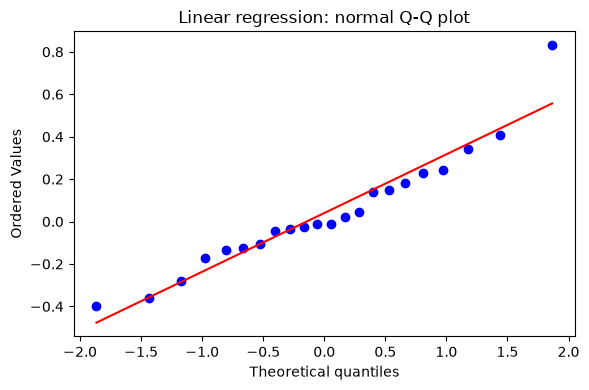

In [39]:
# Linear Regression
linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

# Train
linear_model.fit(X_train, y_train)

# Predict
linear_predictions = linear_model.predict(X_test)

# Calculate residuals
linear_residuals = np.asarray(y_test).ravel() - linear_predictions

# MAE and test normality
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_statistic, linear_p = stats.normaltest(linear_residuals)

print("Model: Linear regression")
print(f"Test MAE: {linear_mae:.4f}")
print(f"Mean residual: {linear_residuals.mean():.4f}")
print(f"Normality test statistic: {linear_statistic:.4f}")
print(f"Normality p-value: {linear_p:.6g}")

# Plot the normal Q-Q plot
fig, ax = plt.subplots(figsize=(6, 4))

stats.probplot(linear_residuals, dist="norm", plot=ax)
ax.set_title("Linear regression: normal Q-Q plot")

plt.tight_layout()
plt.show()

In linear regression method, the p-value is lower than the 5% significance level, so we reject the null hypothesis of normally distributed residuals. In the normal Q-Q plot, most residuals lie close to the reference line, but the largest positive residual deviates above the line, which means the non-normality of tail residuals.

Model: SVR
Test MAE: 0.2218
Mean residual: 0.1379
Normality test statistic: 12.3384
Normality p-value: 0.00209289


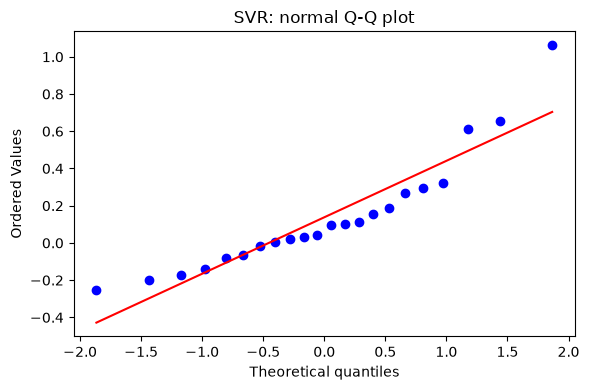

In [40]:
# SVM-SVR
svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)

svr_model.fit(X_train, y_train)

# Predict and calculate residuals
svr_predictions = svr_model.predict(X_test)
svr_residuals = np.asarray(y_test).ravel() - svr_predictions

# MAE and test normality
svr_mae = mean_absolute_error(y_test, svr_predictions)
svr_statistic, svr_p = stats.normaltest(svr_residuals)

print("Model: SVR")
print(f"Test MAE: {svr_mae:.4f}")
print(f"Mean residual: {svr_residuals.mean():.4f}")
print(f"Normality test statistic: {svr_statistic:.4f}")
print(f"Normality p-value: {svr_p:.6g}")

# Plot the normal Q-Q plot
fig, ax = plt.subplots(figsize=(6, 4))

stats.probplot(svr_residuals, dist="norm", plot=ax)
ax.set_title("SVR: normal Q-Q plot")

plt.tight_layout()
plt.show()

In SVM-SVR method, the p-value is lower than the 5% significance level, so we reject the null hypothesis of normally distributed residuals. In the normal Q-Q plot, there is also a large deviation at the upper tail of the residuals, although most residuals are close to the reference line. Therefore, the results also show the non-normality of residuals.

Model: Decision tree
Test MAE: 0.2259
Mean residual: 0.0731
Normality test statistic: 2.3167
Normality p-value: 0.314005


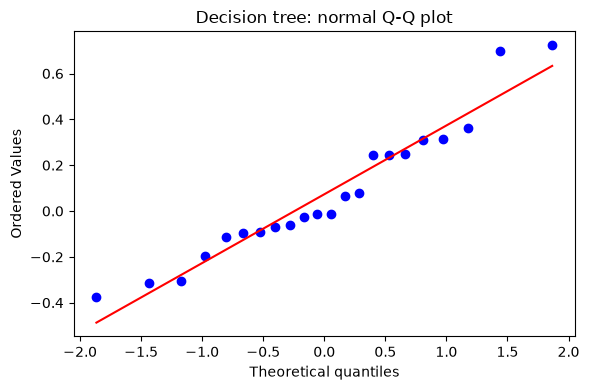

In [41]:
# Decision Tree
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

tree_model.fit(X_train, y_train)

# Predict and calculate residuals
tree_predictions = tree_model.predict(X_test)
tree_residuals = np.asarray(y_test).ravel() - tree_predictions

# MAE and test normality
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_statistic, tree_p = stats.normaltest(tree_residuals)

print("Model: Decision tree")
print(f"Test MAE: {tree_mae:.4f}")
print(f"Mean residual: {tree_residuals.mean():.4f}")
print(f"Normality test statistic: {tree_statistic:.4f}")
print(f"Normality p-value: {tree_p:.6g}")

# Plot the normal Q-Q plot
fig, ax = plt.subplots(figsize=(6, 4))

stats.probplot(tree_residuals, dist="norm", plot=ax)
ax.set_title("Decision tree: normal Q-Q plot")

plt.tight_layout()
plt.show()

In Decision Tree method, the p-value is larger than the 5% significance level, so we do not have enough statistical evidence to reject the null hypothesis of normally distributed residuals. In the normal Q-Q plot, most residuals lie approximately along the reference line, although some deviations appear in the upper tail.

**Question 5**

Classification

(a)

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_absolute_error

In [43]:
cancer = load_breast_cancer()

X_class = cancer.data
y_class = cancer.target

X_class_train, X_class_test, y_class_train, y_class_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=42,
    stratify=y_class
)

class_scaler = StandardScaler()

X_class_train_scaled = class_scaler.fit_transform(X_class_train)
X_class_test_scaled = class_scaler.transform(X_class_test)

# Convert training and test data to PyTorch
X_class_train_tensor = torch.tensor(
    X_class_train_scaled,
    dtype=torch.float32
)

y_class_train_tensor = torch.tensor(
    y_class_train,
    dtype=torch.float32
).reshape(-1, 1)

X_class_test_tensor = torch.tensor(
    X_class_test_scaled,
    dtype=torch.float32
)

class_train_dataset = TensorDataset(
    X_class_train_tensor,
    y_class_train_tensor
)

print("Training observations:", len(X_class_train))
print("Test observations:", len(X_class_test))

Training observations: 455
Test observations: 114


In [44]:
class_baseline = LogisticRegression(max_iter=5000)

class_baseline.fit(
    X_class_train_scaled,
    y_class_train
)

class_baseline_predictions = class_baseline.predict(
    X_class_test_scaled
)

class_baseline_accuracy = accuracy_score(
    y_class_test,
    class_baseline_predictions
)

print("Model: sklearn logistic regression")
print(f"Test accuracy: {class_baseline_accuracy:.4f}")

Model: sklearn logistic regression
Test accuracy: 0.9825


Epoch 200: loss = 0.072755
Epoch 400: loss = 0.062288
Epoch 600: loss = 0.057635
Epoch 800: loss = 0.054827
Epoch 1000: loss = 0.052934

Custom logistic test accuracy: 0.9737


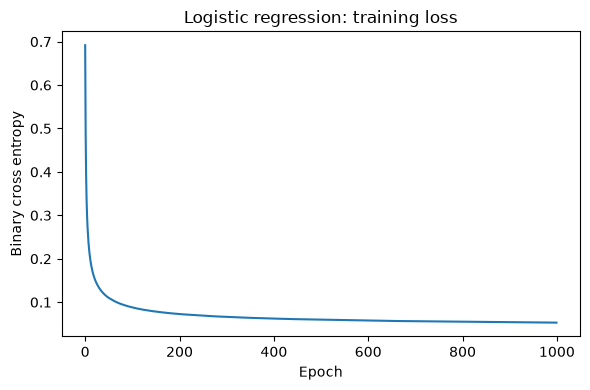

In [45]:
torch.manual_seed(42)

logistic_loader = DataLoader(
    class_train_dataset,
    batch_size=32,
    shuffle=True
)

logistic_model = nn.Linear(X_class_train_tensor.shape[1], 1)

logistic_optimizer = torch.optim.SGD(
    logistic_model.parameters(),
    lr=0.01
)

logistic_epochs = 1000
logistic_history = []

# Train
logistic_model.train()

for epoch in range(logistic_epochs):
    total_loss = 0.0

    for X_batch, y_batch in logistic_loader:
        logits = logistic_model(X_batch)

        probabilities = torch.sigmoid(logits)
        probabilities = probabilities.clamp(1e-7, 1 - 1e-7)

        # binary cross-entropy loss
        loss = -(
            y_batch * torch.log(probabilities)
            + (1 - y_batch) * torch.log(1 - probabilities)
        ).mean()

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite logistic loss.")

        logistic_optimizer.zero_grad()
        loss.backward()
        logistic_optimizer.step()

        total_loss += loss.item() * len(X_batch)

    epoch_loss = total_loss / len(class_train_dataset)
    logistic_history.append(epoch_loss)

    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch + 1}: loss = {epoch_loss:.6f}")

# Evaluate
logistic_model.eval()

with torch.no_grad():
    logistic_test_probabilities = torch.sigmoid(
        logistic_model(X_class_test_tensor)
    ).numpy().ravel()

logistic_test_predictions = (
    logistic_test_probabilities >= 0.5
).astype(int)

logistic_accuracy = accuracy_score(
    y_class_test,
    logistic_test_predictions
)

print(f"\nCustom logistic test accuracy: {logistic_accuracy:.4f}")

# Training curve
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(logistic_history)
ax.set_title("Logistic regression: training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary cross entropy")
plt.tight_layout()
plt.show()

(b)

Epoch 200: loss = 0.058825
Epoch 400: loss = 0.052839
Epoch 600: loss = 0.049950
Epoch 800: loss = 0.048119
Epoch 1000: loss = 0.046798

Probit test accuracy: 0.9649


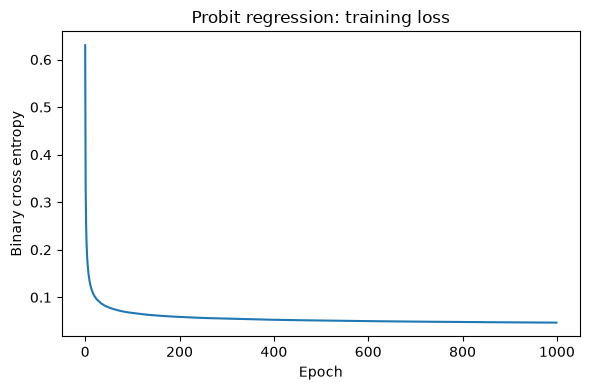

In [46]:
torch.manual_seed(42)

probit_loader = DataLoader(
    class_train_dataset,
    batch_size=32,
    shuffle=True
)

probit_model = nn.Linear(X_class_train_tensor.shape[1], 1)

probit_optimizer = torch.optim.SGD(
    probit_model.parameters(),
    lr=0.01
)

standard_normal = torch.distributions.Normal(
    loc=0.0,
    scale=1.0
)

probit_epochs = 1000
probit_history = []

# Train
probit_model.train()

for epoch in range(probit_epochs):
    total_loss = 0.0

    for X_batch, y_batch in probit_loader:
        linear_output = probit_model(X_batch)

        probabilities = standard_normal.cdf(linear_output)
        probabilities = probabilities.clamp(1e-7, 1 - 1e-7)

        # Binary cross-entropy loss
        loss = -(
            y_batch * torch.log(probabilities)
            + (1 - y_batch) * torch.log(1 - probabilities)
        ).mean()

        if not torch.isfinite(loss).item():
            raise RuntimeError("Non-finite probit loss.")

        probit_optimizer.zero_grad()
        loss.backward()
        probit_optimizer.step()

        total_loss += loss.item() * len(X_batch)

    epoch_loss = total_loss / len(class_train_dataset)
    probit_history.append(epoch_loss)

    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch + 1}: loss = {epoch_loss:.6f}")

# Evaluate
probit_model.eval()

with torch.no_grad():
    probit_test_probabilities = standard_normal.cdf(
        probit_model(X_class_test_tensor)
    ).numpy().ravel()

probit_test_predictions = (
    probit_test_probabilities >= 0.5
).astype(int)

probit_accuracy = accuracy_score(
    y_class_test,
    probit_test_predictions
)

print(f"\nProbit test accuracy: {probit_accuracy:.4f}")

# Training curve
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(probit_history)
ax.set_title("Probit regression: training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Binary cross entropy")
plt.tight_layout()
plt.show()

In [47]:
classification_results = pd.DataFrame({
    "Model": [
        "sklearn logistic regression",
        "PyTorch logistic regression",
        "PyTorch probit regression"
    ],
    "Test accuracy": [
        class_baseline_accuracy,
        logistic_accuracy,
        probit_accuracy
    ]
})

display(classification_results)

,Model,Test accuracy
0,sklearn logistic regression,0.982456
1,PyTorch logistic regression,0.973684
2,PyTorch probit regression,0.964912


Compare to the baseline, PyTorch logistic regression performs approximately 0.88% lower than the baseline model, and PyTorch probit regression performs 1.75% lower than the baseline model. Both of them perform slightly worse than the baseline model.

Regression

(a)

In [48]:
ale_df = pd.read_csv("mcs_ds_edited_iter_shuffled.csv")

print("Data shape:", ale_df.shape)
display(ale_df.head())

# Predictors
X_reg = ale_df.iloc[:, :4].to_numpy(dtype=float)

# ALE target
y_reg = ale_df.iloc[:, 4].to_numpy(dtype=float)

if not np.isfinite(X_reg).all() or not np.isfinite(y_reg).all():
    raise ValueError("The ALE data contains missing or non-finite values.")

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

reg_scaler = StandardScaler()

X_reg_train_scaled = reg_scaler.fit_transform(X_reg_train)
X_reg_test_scaled = reg_scaler.transform(X_reg_test)

# Convert to PyTorch tensors
X_reg_train_tensor = torch.tensor(
    X_reg_train_scaled,
    dtype=torch.float32
)

y_reg_train_tensor = torch.tensor(
    y_reg_train,
    dtype=torch.float32
).reshape(-1, 1)

X_reg_test_tensor = torch.tensor(
    X_reg_test_scaled,
    dtype=torch.float32
)

reg_train_dataset = TensorDataset(
    X_reg_train_tensor,
    y_reg_train_tensor
)

print("Training observations:", len(X_reg_train))
print("Test observations:", len(X_reg_test))

Data shape: (107, 6)


,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


Training observations: 85
Test observations: 22


In [49]:
reg_baseline = LinearRegression()

reg_baseline.fit(
    X_reg_train_scaled,
    y_reg_train
)

reg_baseline_predictions = reg_baseline.predict(
    X_reg_test_scaled
)

reg_baseline_mae = mean_absolute_error(
    y_reg_test,
    reg_baseline_predictions
)

print("Model: sklearn linear regression")
print(f"Test MAE: {reg_baseline_mae:.4f}")

Model: sklearn linear regression
Test MAE: 0.1954


Epoch 400: loss = 0.050735
Epoch 800: loss = 0.050697
Epoch 1200: loss = 0.050723
Epoch 1600: loss = 0.050655
Epoch 2000: loss = 0.050663

Linear + MSE test MAE: 0.1955


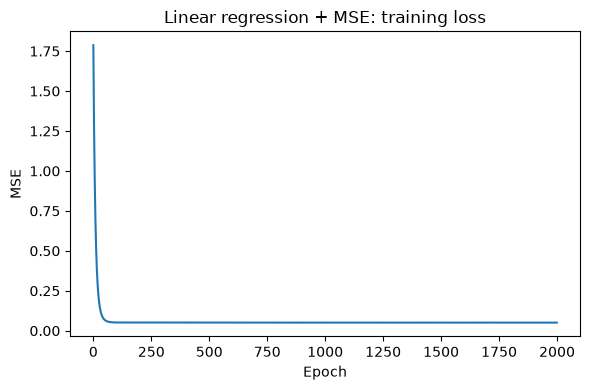

In [50]:
torch.manual_seed(42)

mse_loader = DataLoader(
    reg_train_dataset,
    batch_size=32,
    shuffle=True
)

mse_model = nn.Linear(X_reg_train_tensor.shape[1], 1)

mse_optimizer = torch.optim.SGD(
    mse_model.parameters(),
    lr=0.01
)

mse_epochs = 2000
mse_history = []

# Train
mse_model.train()

for epoch in range(mse_epochs):
    total_loss = 0.0

    for X_batch, y_batch in mse_loader:
        predictions = mse_model(X_batch)

        # Custom mean squared error
        loss = ((y_batch - predictions) ** 2).mean()

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                "Non-finite MSE loss. Try a smaller learning rate."
            )

        mse_optimizer.zero_grad()
        loss.backward()
        mse_optimizer.step()

        total_loss += loss.item() * len(X_batch)

    epoch_loss = total_loss / len(reg_train_dataset)
    mse_history.append(epoch_loss)

    if (epoch + 1) % 400 == 0:
        print(f"Epoch {epoch + 1}: loss = {epoch_loss:.6f}")

# Evaluate using MAE
mse_model.eval()

with torch.no_grad():
    mse_test_predictions = mse_model(
        X_reg_test_tensor
    ).numpy().ravel()

mse_mae = mean_absolute_error(
    y_reg_test,
    mse_test_predictions
)

print(f"\nLinear + MSE test MAE: {mse_mae:.4f}")

# Training curve
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(mse_history)
ax.set_title("Linear regression + MSE: training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE")
plt.tight_layout()
plt.show()

(b)

Epoch 400: loss = 0.997710
Epoch 800: loss = 0.997697
Epoch 1200: loss = 0.997703
Epoch 1600: loss = 0.997685
Epoch 2000: loss = 0.997686

Linear + Student-t test MAE: 0.1943


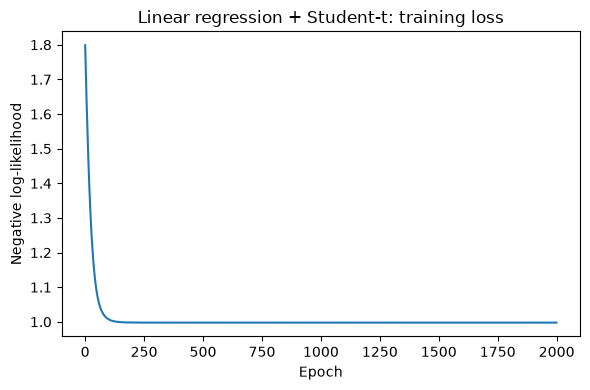

In [51]:
torch.manual_seed(42)

t_loader = DataLoader(
    reg_train_dataset,
    batch_size=32,
    shuffle=True
)

t_model = nn.Linear(X_reg_train_tensor.shape[1], 1)

t_optimizer = torch.optim.SGD(
    t_model.parameters(),
    lr=0.01
)

student_t = torch.distributions.StudentT(
    df=5.0,
    loc=0.0,
    scale=1.0
)

t_epochs = 2000
t_history = []

# Train
t_model.train()

for epoch in range(t_epochs):
    total_loss = 0.0

    for X_batch, y_batch in t_loader:
        predictions = t_model(X_batch)

        residuals = y_batch - predictions

        # Student-t negative log-likelihood
        loss = -student_t.log_prob(residuals).mean()

        if not torch.isfinite(loss).item():
            raise RuntimeError(
                "Non-finite Student-t loss. Try a smaller learning rate."
            )

        t_optimizer.zero_grad()
        loss.backward()
        t_optimizer.step()

        total_loss += loss.item() * len(X_batch)

    epoch_loss = total_loss / len(reg_train_dataset)
    t_history.append(epoch_loss)

    if (epoch + 1) % 400 == 0:
        print(f"Epoch {epoch + 1}: loss = {epoch_loss:.6f}")

# Evaluate using MAE
t_model.eval()

with torch.no_grad():
    t_test_predictions = t_model(
        X_reg_test_tensor
    ).numpy().ravel()

t_mae = mean_absolute_error(
    y_reg_test,
    t_test_predictions
)

print(f"\nLinear + Student-t test MAE: {t_mae:.4f}")

# Training curve
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(t_history)
ax.set_title("Linear regression + Student-t: training loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Negative log-likelihood")
plt.tight_layout()
plt.show()

In [52]:
regression_results = pd.DataFrame({
    "Model": [
        "sklearn linear regression",
        "PyTorch linear regression + MSE",
        "PyTorch linear regression + Student-t"
    ],
    "Test MAE": [
        reg_baseline_mae,
        mse_mae,
        t_mae
    ]
})

display(regression_results)

,Model,Test MAE
0,sklearn linear regression,0.195393
1,PyTorch linear regression + MSE,0.195465
2,PyTorch linear regression + Student-t,0.194258


Compare to the baseline model, the new two models perform similarly to it. The PyTorch linear regression has the highest test MAE value, which is consistent with the baseline model, even they use different optimization methods. The t-distribution model has the lowest test MAE value, showing a slight reduction in this model compare to the baseline model.